Students: Karina and Nicolas 

Instruction: Take a picture of a cluttered scenario with the presence of several objects, resize the picture as to be 448x336 pixels. Read and show the picture using OpenCV.

**Part3.Load and Resize**

In [26]:
import cv2

# Read JPEG image
image = cv2.imread("imagen.jpeg")

# Check if the image was loaded
if image is None:
    raise FileNotFoundError("Image not found")

# Convert JPEG to PNG
cv2.imwrite("imagen.png", image)

print("Image successfully converted to PNG")

Image successfully converted to PNG


In [27]:
# Read PNG image
image = cv2.imread("imagen.png")

# Resize to 448x336 pixels
resized = cv2.resize(image, (448, 336))

# Save resized image
cv2.imwrite("photo_resized.png", resized)

# Verify dimensions
print("Resized dimensions:", resized.shape)

Resized dimensions: (336, 448, 3)


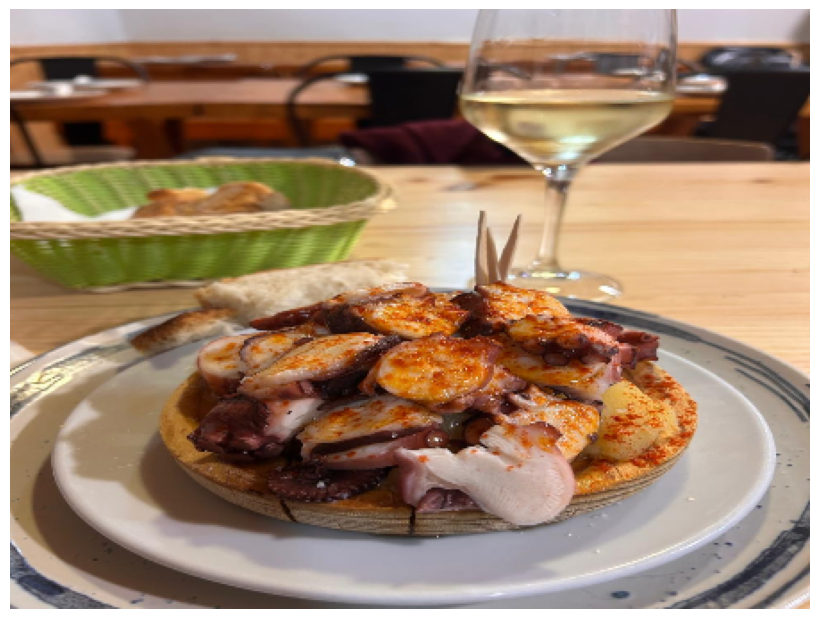

In [28]:
import matplotlib.pyplot as plt

# Convert BGR to RGB

resized_rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

fig = plt.figure(figsize=(8, 6), frameon=False)
ax = fig.add_axes((0, 0, 1, 1))
ax.imshow(resized_rgb)
ax.set_axis_off()

# Display image 
plt.imshow(resized_rgb)
plt.axis("off")
plt.show()

**Part 4.Filter aplication**

Parameters to play with: 
- **ksize:** Size of the filter, for example (21, 21).
- **sigma:** Controls the spread of the Gaussian envelope.
- **theta:** Orientation of the filter in radians.
- **lambd:** Wavelength; determines the spatial frequency.
- **gamma:** Controls how elongated the filter is.
- **psi:** Phase of the wave, which changes the filter's response.

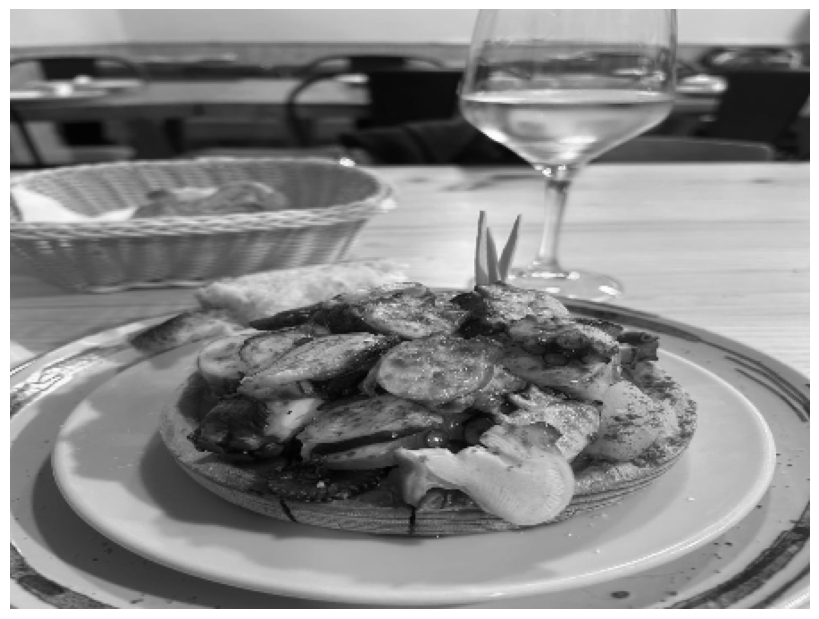

In [29]:
#Preprocessing: Conver image in gray acale so we can use a unique value of intensity per pixel instead of 3 values (RGB) per pixel.
import numpy as np
import matplotlib.pyplot as plt

# Convert image to grayscale
gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
fig = plt.figure(figsize=(8, 6), frameon=False)
#Removing blank space around the image
ax = fig.add_axes((0, 0, 1, 1))
ax.imshow(resized_rgb)
ax.set_axis_off()
# Display grayscale image
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

In [30]:
#Filter implementation
# Four orientations
angles = [0, 45, 90, 135]

# Store filtered images
filtered_images = []

for angle in angles:

    # Create Gabor kernel
    kernel = cv2.getGaborKernel(
        (21, 21),          # Kernel size
        4.0,               # Sigma
        np.deg2rad(angle), # Orientation
        10.0,              # Wavelength
        0.5,               # Gamma
        0                 # Phase
    )

    # Apply filter
    filtered = cv2.filter2D(gray.astype(np.float32), cv2.CV_32F, kernel)

    filtered_images.append(np.abs(filtered)) 

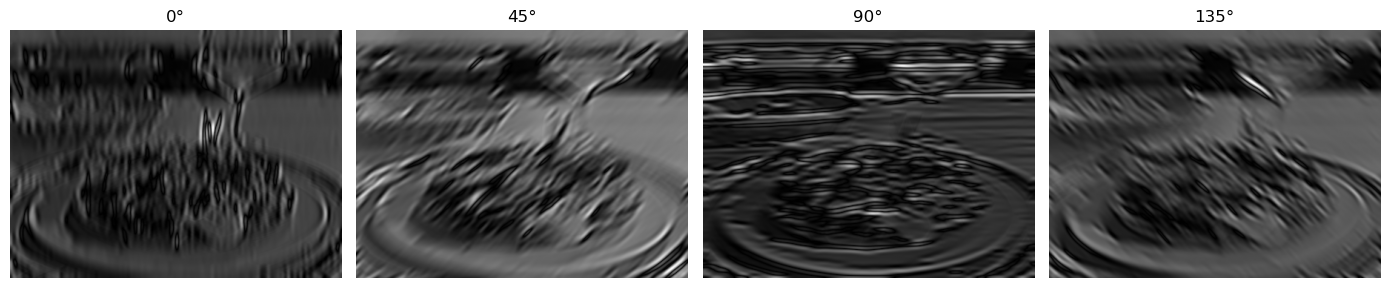

In [31]:
#Show result 
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i in range(4):
    axes[i].imshow(filtered_images[i], cmap="gray")
    axes[i].set_title(f"{angles[i]}°")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

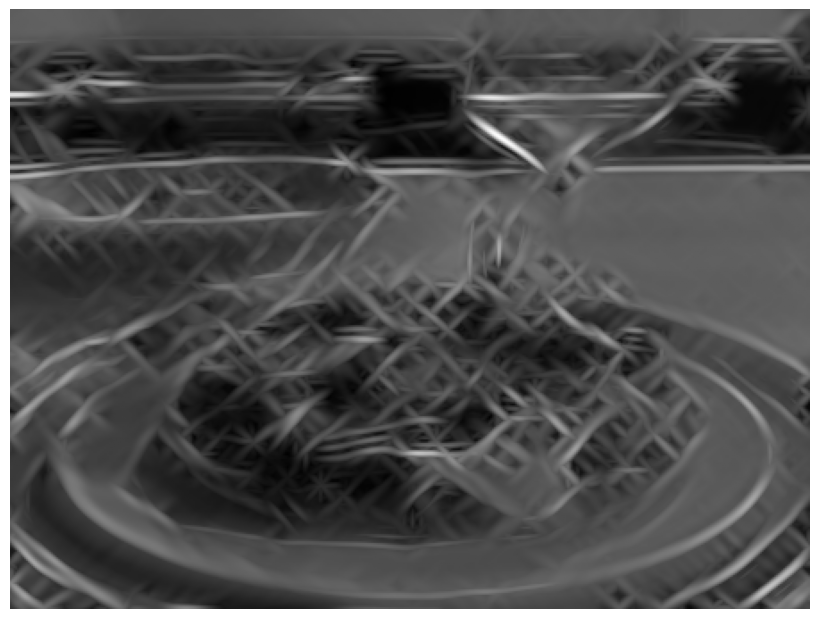

In [32]:
# Maximum response at each pixel
combined = np.maximum.reduce(filtered_images)

# Create figure without borders
fig = plt.figure(figsize=(8, 6), frameon=False)
ax = fig.add_axes((0, 0, 1, 1))

# Display combined Gabor result
ax.imshow(combined, cmap="gray")
ax.set_axis_off()

plt.show()

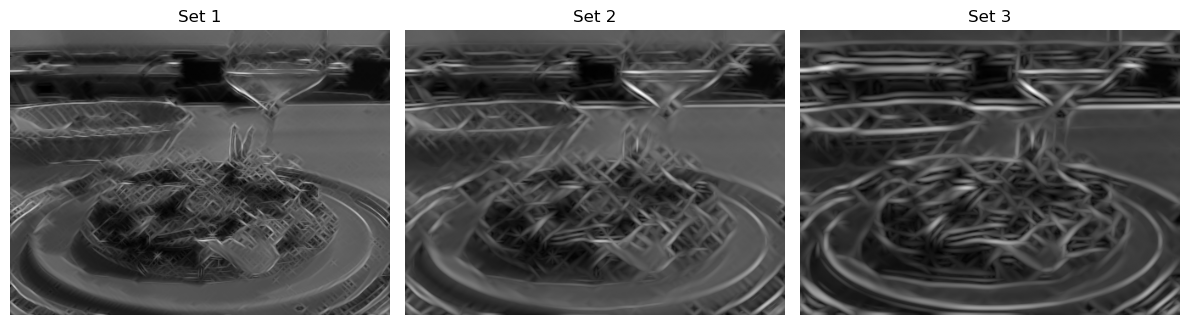

In [33]:
#Playing with differentparameters:

#  Three parameter sets for size, sigma, lambd, gamma
parameters = [
    (11, 2.0, 5.0, 0.5),
    (21, 4.0, 10.0, 0.5),
    (31, 6.0, 15.0, 0.8)
]

angles = [0, 45, 90, 135]
results = []

for size, sigma, lambd, gamma in parameters:

    filtered_images = []

    for angle in angles:

        kernel = cv2.getGaborKernel(
            (size, size),
            sigma,
            np.deg2rad(angle),
            lambd,
            gamma,
            0
        )

        filtered = cv2.filter2D(
            gray.astype(np.float32),
            cv2.CV_32F,
            kernel
        )

        filtered_images.append(np.abs(filtered))   # ← CAMBIO
    # Combine using maximum value
    combined = np.maximum.reduce(filtered_images)

    results.append(combined)

# Display three results
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for i in range(3):
    axes[i].imshow(results[i], cmap="gray")
    axes[i].set_title(f"Set {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Conclusion of the exercise: 

A Gabor filter was applied to the grayscale image using four different orientations: 0°, 45°, 90°, and 135°. Each orientation helps detect different edges and textures in the image. The four results were combined by selecting the maximum value for each pixel.

Three different parameter sets were tested by changing the kernel size, sigma, wavelength, and gamma. The first set uses a smaller filter to detect finer details, while the second set focuses on medium-sized patterns. The third set uses a larger filter to detect broader structures.

This experiment helps us understand how Gabor filters work and how changing their parameters affects the detection of textures and edges in an image.

Part 5: Apply the Canny Edge detector. Show the result and compare to the result from the
Gabor.


(336, 448) uint8 [  0 255]


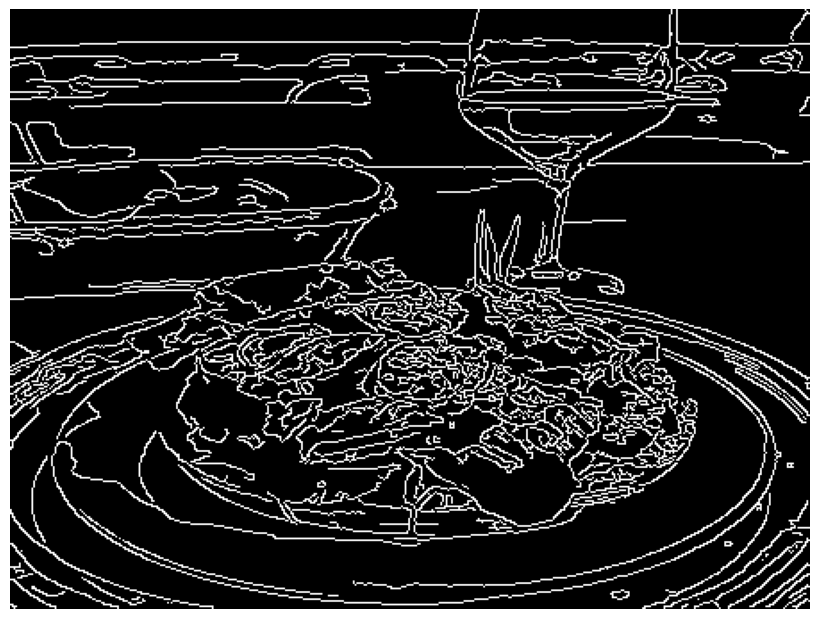

In [34]:
# Exercise 5: Canny edge detector

# Remove noise by blurring with a Gaussian filter (as in the Laplace example, Lecture 3)
blurred = cv2.GaussianBlur(gray, (3, 3), 0)  

# Apply Canny to the blurred grayscale image
edges = cv2.Canny(blurred, 50, 150)

# Check the output
print(edges.shape, edges.dtype, np.unique(edges))

# Show the result
fig = plt.figure(figsize=(8, 6), frameon=False)
ax = fig.add_axes((0, 0, 1, 1))
ax.imshow(edges, cmap="gray")
ax.set_axis_off()
plt.show()

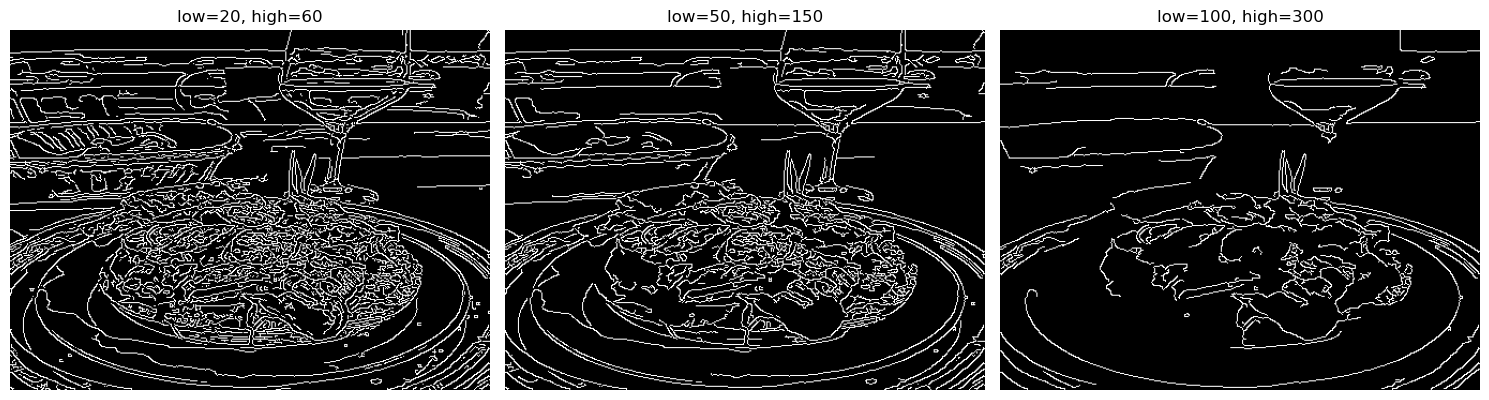

In [35]:
# Try different threshold pairs (low, high)
thresholds = [(20, 60), (50, 150), (100, 300)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (low, high) in enumerate(thresholds):
    edges_i = cv2.Canny(blurred, low, high)   
    axes[i].imshow(edges_i, cmap="gray")
    axes[i].set_title(f"low={low}, high={high}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

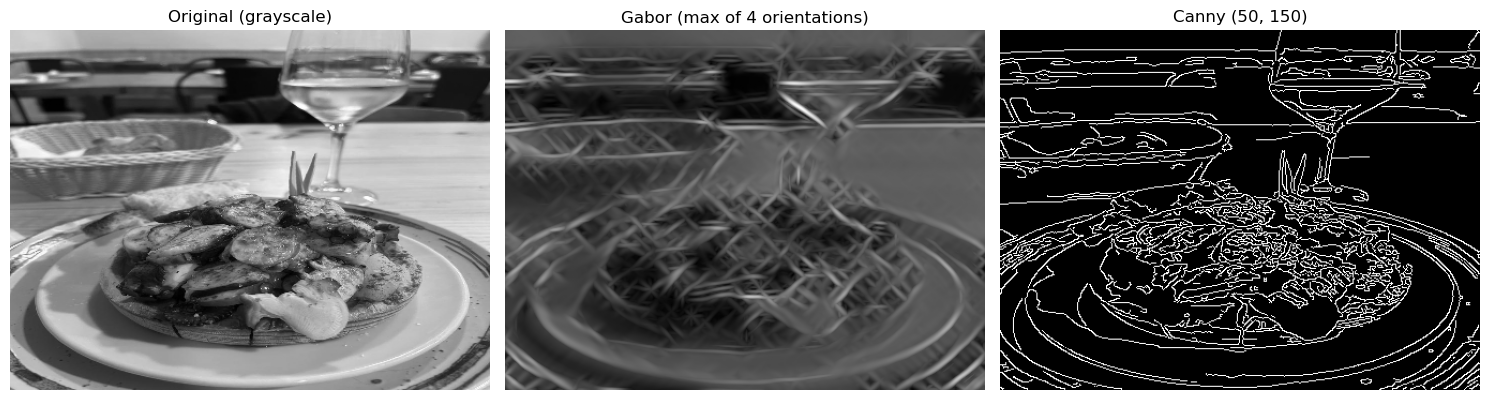

In [36]:
# Compare Gabor (combined, set 2) vs Canny
gabor_result = results[1]          # same parameters as cell 8: (21, 4.0, 10.0, 0.5)
canny_result = cv2.Canny(blurred, 50, 150)   

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original (grayscale)")

axes[1].imshow(gabor_result, cmap="gray")
axes[1].set_title("Gabor (max of 4 orientations)")

axes[2].imshow(canny_result, cmap="gray")
axes[2].set_title("Canny (50, 150)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

The choice of thresholds has a strong effect on Canny: low thresholds add a lot of noise (textures and small brightness changes appear as edges), while high thresholds keep only the strongest contours but can break weaker edges, such as the glass stem. Medium thresholds (50, 150) gave the best balance for our image.

Compared to Gabor, Canny gives thin, continuous and binary edges, which makes it better for outlining object shapes. Gabor gives a continuous and blurrier response that depends on orientation and stripe size, so it is more useful for detecting textures and repeated patterns than clean contours

Part 6: Implement a Gaussian and a Laplacian pyramid. Show the results. Comment on
the high and low frequencies and their locations in the results.

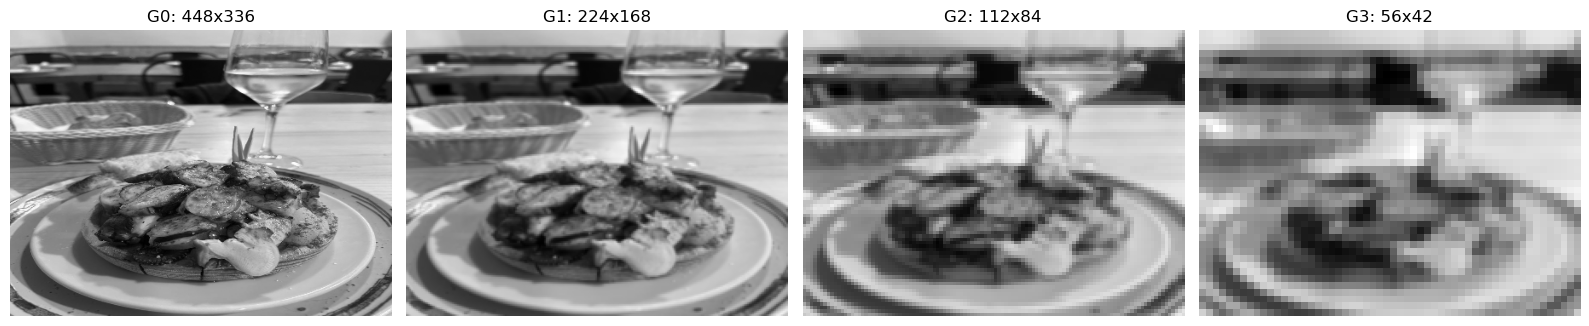

In [37]:
# Exercise 6: Gaussian pyramid
levels = 4
gaussian_pyramid = [gray]

for i in range(levels - 1):
    smaller = cv2.pyrDown(gaussian_pyramid[-1])   # blur + halve the size
    gaussian_pyramid.append(smaller)

# Show the levels
fig, axes = plt.subplots(1, levels, figsize=(16, 4))
for i, level in enumerate(gaussian_pyramid):
    axes[i].imshow(level, cmap="gray")
    axes[i].set_title(f"G{i}: {level.shape[1]}x{level.shape[0]}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

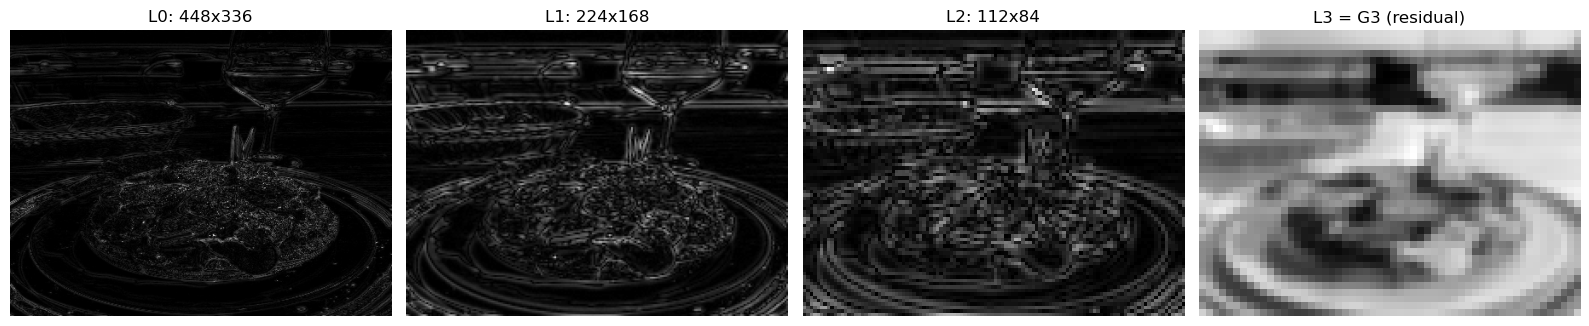

In [38]:
# Laplacian pyramid: L_i = G_i - expand(G_{i+1})
laplacian_pyramid = []

for i in range(levels - 1):
    current = gaussian_pyramid[i]
    smaller = gaussian_pyramid[i + 1]

    # Expand the smaller level back to the size of the current one
    expanded = cv2.pyrUp(smaller, dstsize=(current.shape[1], current.shape[0]))

    # Difference = details lost between the two levels (use float to keep negatives)
    detail = current.astype(np.float32) - expanded.astype(np.float32)
    laplacian_pyramid.append(detail)

# The last level is the smallest Gaussian level (low frequencies)
laplacian_pyramid.append(gaussian_pyramid[-1].astype(np.float32))

# Show the levels
fig, axes = plt.subplots(1, levels, figsize=(16, 4))
for i, level in enumerate(laplacian_pyramid):
    if i < levels - 1:
        axes[i].imshow(np.abs(level), cmap="gray")   # details: show their strength
        axes[i].set_title(f"L{i}: {level.shape[1]}x{level.shape[0]}")
    else:
        axes[i].imshow(level, cmap="gray")           # residual: low frequencies
        axes[i].set_title(f"L{i} = G{i} (residual)")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

The Gaussian pyramid shows that each level keeps less detail: by G3 (56×42) only the large shapes and brightness regions remain (the light plate, the dark food and the background), which correspond to the low frequencies of the image. The Laplacian pyramid shows the details lost between each pair of levels, which are the high frequencies. L0 contains the finest details (the texture of the food and the weave of the bread basket), while L1 and L2 contain progressively larger structures, such as the contour of the glass and the rings of the plate.

In all Laplacian levels, the high frequencies are located at object edges and textured regions, while smooth areas such as the table, the wine and the centre of the plate appear black, since there is almost no change in intensity there. Their information is kept only in the residual level (L3), which contains the low frequencies.